<a href="https://colab.research.google.com/github/VictorTrasancos/Telco-Customer-Churn/blob/main/Telco_Customer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parte 1 - Preparação dos Dados

In [11]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print('Dimensões', df.shape)
display(df.head())

df.dtypes

Dimensões (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [12]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print('Dimensões', df.shape)
display(df.head())

df.dtypes

# Clientes com tenure = 0 ainda não possuem valores a ser cobrado
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.loc[df["TotalCharges"].isna() & (df["tenure"] == 0), "TotalCharges"] = 0.0

# Binarização de Churn e SeniorCitizen
df['y'] = df['Churn'].map({'Yes': 1, 'No': 0})
df['SeniorCitizen'] = df['SeniorCitizen'].replace({0: 'No', 1: 'Yes'})

# CustomerID não tem valor preditivo, apenas confundiria o modelo
X = df.drop(columns=['customerID', 'Churn', 'y'])
y = df['y']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Dimensões do conjunto de Treino: {X_train.shape}")
print(f"Dimensões do conjunto de Teste: {X_test.shape}")

print(X_train.info())

Dimensões (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dimensões do conjunto de Treino: (5634, 19)
Dimensões do conjunto de Teste: (1409, 19)
<class 'pandas.core.frame.DataFrame'>
Index: 5634 entries, 2142 to 860
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            5634 non-null   object 
 1   SeniorCitizen     5634 non-null   object 
 2   Partner           5634 non-null   object 
 3   Dependents        5634 non-null   object 
 4   tenure            5634 non-null   int64  
 5   PhoneService      5634 non-null   object 
 6   MultipleLines     5634 non-null   object 
 7   InternetService   5634 non-null   object 
 8   OnlineSecurity    5634 non-null   object 
 9   OnlineBackup      5634 non-null   object 
 10  DeviceProtection  5634 non-null   object 
 11  TechSupport       5634 non-null   object 
 12  StreamingTV       5634 non-null   object 
 13  StreamingMovies   5634 non-null   object 
 14  Contract          5634 non-null   object 
 15  Paper

# Parte 2 - Análise Exploratória

Proporção de cancelamento
Churn
0    73.45
1    26.55
Name: proportion, dtype: float64
Medidas descritivas para as variáveis númericas por Churn


Churn                       0        1
tenure         count  4138.00  1496.00
               mean     37.44    18.36
               std      24.01    19.64
               min       0.00     1.00
               25%      15.00     2.00
               50%      37.00    10.00
               75%      61.00    30.00
               max      72.00    72.00
MonthlyCharges count  4138.00  1496.00
               mean     61.45    74.30
               std      31.04    24.97
               min      18.25    18.85
               25%      25.15    55.78
               50%      64.85    79.65
               75%      88.70    94.40
               max     118.60   118.35
TotalCharges   count  4138.00  1496.00
               mean   2550.20  1559.30
               std    2324.92  1902.68
               min       0.00    18.85
               25%     574.92   138.69
               50%    1684.75   731.65
               75%    4235.99  2377.59
               max    8594.40  8684.80

Proporção de cancelamento por Contract


,Tamanho_Grupo,Taxa_cancelamento_Perc
StreamingMovies,,
No,2223,33.33
Yes,2197,30.13
No internet service,1214,7.66


Proporção de cancelamento por PaymentMethod


,Tamanho_Grupo,Taxa_cancelamento_Perc
StreamingMovies,,
No,2223,33.33
Yes,2197,30.13
No internet service,1214,7.66


Proporção de cancelamento por InternetService


,Tamanho_Grupo,Taxa_cancelamento_Perc
StreamingMovies,,
No,2223,33.33
Yes,2197,30.13
No internet service,1214,7.66


/tmp/ipykernel_2088/2008821233.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tr, x='Churn', y='tenure', ax=axes[0, 0], palette='Set2')
/tmp/ipykernel_2088/2008821233.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tr, x='Churn', y='MonthlyCharges', ax=axes[0, 1], palette='Set2')
/tmp/ipykernel_2088/2008821233.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tr, x='Contract', y='Churn', errorbar=None, ax=axes[1, 0], palette='Blues_d')
/tmp/ipykernel_2088/2008821233.py:45: FutureWarning: 

Passing `palette` witho

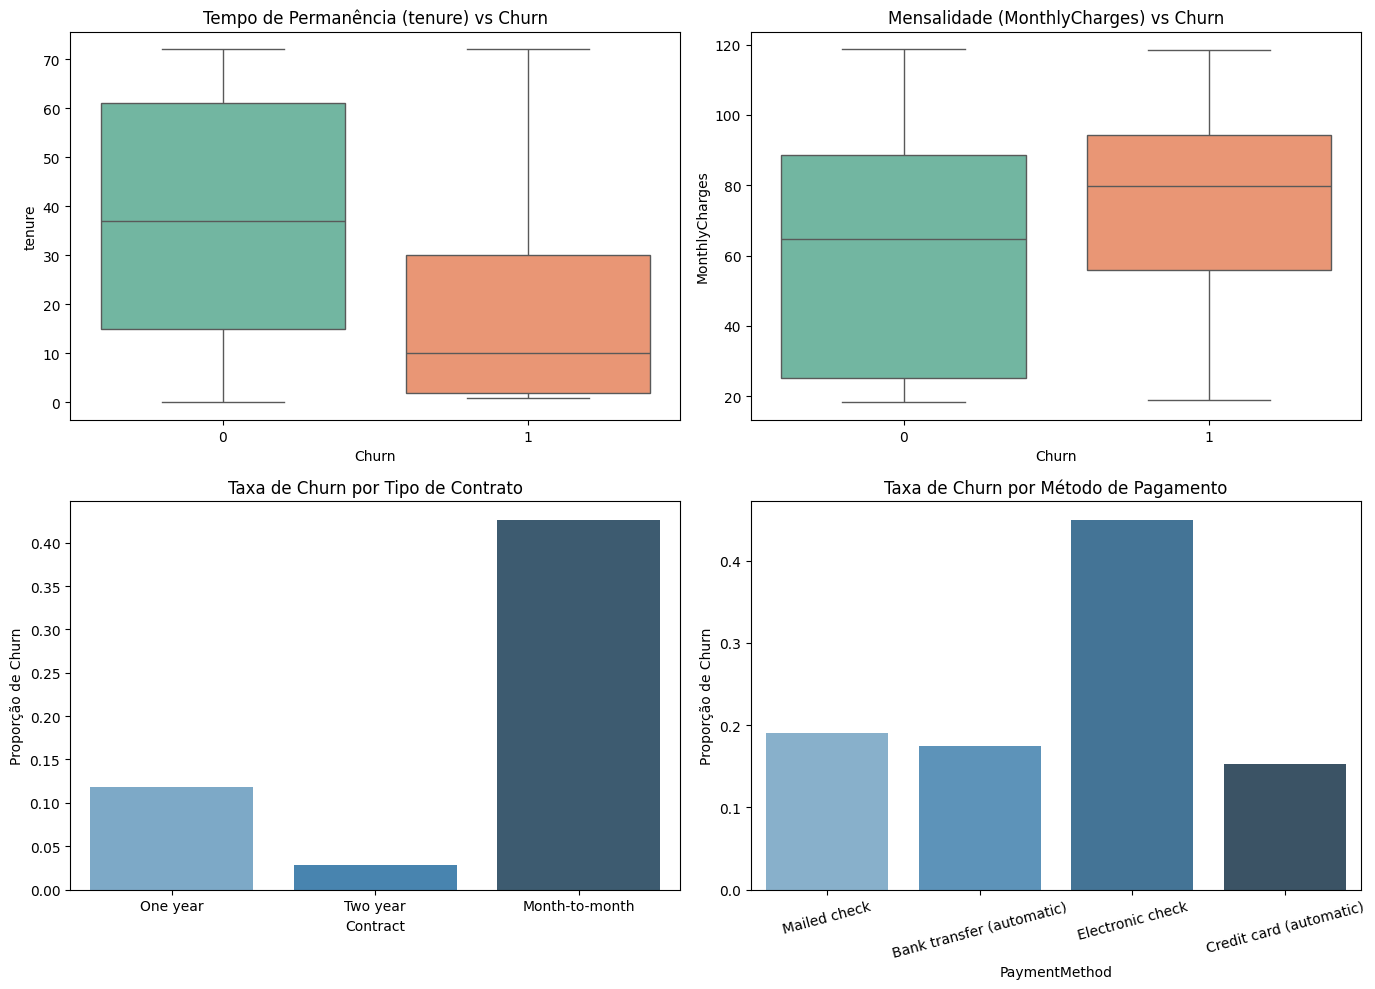

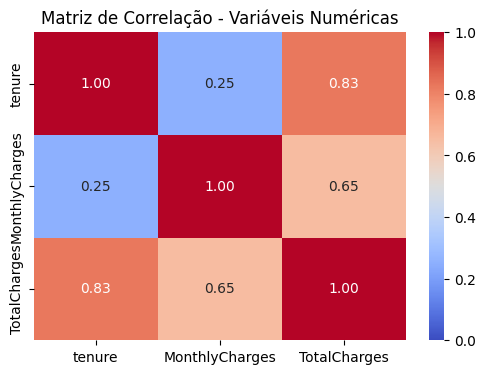

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Evitando vazamento de dados
tr = X_train.copy()
tr['Churn'] = y_train

# Proporção geral de cancelamento
print('Proporção de cancelamento')
print((tr['Churn'].value_counts(normalize = True)*100).round(2))

# Medidas descritivas para as variáveis númericas
num_cols = ['tenure','MonthlyCharges','TotalCharges']
print('Medidas descritivas para as variáveis númericas por Churn')
display(tr.groupby('Churn')[num_cols].describe().round(2).T)

# Grupos e Churn para variáveis categóricas
categ_cols = ['Contract', 'PaymentMethod', 'InternetService']

for categ in categ_cols:
  resumo = tr.groupby(col)['Churn'].agg(
      Tamanho_Grupo = 'size',
      Taxa_cancelamento_Perc ='mean'
  ).round(4)

  resumo['Taxa_cancelamento_Perc'] = resumo['Taxa_cancelamento_Perc']*100
  print(f'Proporção de cancelamento por {categ}')
  display(resumo.sort_values(by='Taxa_cancelamento_Perc', ascending = False))

# Plotagem
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Númericas vs Churn
sns.boxplot(data=tr, x='Churn', y='tenure', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Tempo de Permanência (tenure) vs Churn')

sns.boxplot(data=tr, x='Churn', y='MonthlyCharges', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Mensalidade (MonthlyCharges) vs Churn')

# Categóricas vs Churn
sns.barplot(data=tr, x='Contract', y='Churn', errorbar=None, ax=axes[1, 0], palette='Blues_d')
axes[1, 0].set_title('Taxa de Churn por Tipo de Contrato')
axes[1, 0].set_ylabel('Proporção de Churn')

sns.barplot(data=tr, x='PaymentMethod', y='Churn', errorbar=None, ax=axes[1, 1], palette='Blues_d')
axes[1, 1].set_title('Taxa de Churn por Método de Pagamento')
axes[1, 1].set_ylabel('Proporção de Churn')
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(tr[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=0, vmax=1)
plt.title('Matriz de Correlação - Variáveis Numéricas')
plt.show()

# Parte 3 - Seleção e Transformação das Variáveis

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [19]:
# Seleção e Transformação de variáveis

def engenharia_atributos(d):
  d = d.copy()

  servicos = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

  # Eliminando redundâncias
  for c in servicos:
    d[c] = d[c].replace({'No internet service': 'No'})
  d['MultipleLines'] = d['MultipleLines'].replace({'No phone service': 'No'})

  # Quantidade de serviços usados pelos clientes
  d['num_servicos_extras'] = (d[servicos] == 'Yes').sum(axis=1)

  # Houve aumento da mensalidade do cliente?
  d['ticket_medio'] = d['TotalCharges'] / d['tenure'].clip(lower=1)
  d['dif_preco'] = d['MonthlyCharges'] - d['ticket_medio']

  return d

X_train_eng = engenharia_atributos(X_train)
X_test_eng = engenharia_atributos(X_test)

# Removemos TotalCharges por sua redundância com tenure
num_cols = ['tenure', 'MonthlyCharges', 'num_servicos_extras', 'dif_preco']
cat_cols = X_train_eng.select_dtypes(include=['object']).columns.tolist()

# Aplicamos o StandarScaler para variáveis numéricas
# Aplicamos o OneHotEnconder para as categóricas, mas filtramos as que já são binárias para evitar duplicatas
preprocessor_eng = ColumnTransformer(transformers=[
    ('num',StandardScaler(),num_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), cat_cols)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelo_teste = LogisticRegression(max_iter=1000, random_state=42)

# Analisando com os dados originais(incluindo total charges)
num_base = ['tenure', 'MonthlyCharges', 'TotalCharges']
preprocessor_base = ColumnTransformer([
    ('num', StandardScaler(), num_base),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), cat_cols)
])
pipe_base = Pipeline([('prep',preprocessor_base), ('clf',modelo_teste)])
score_base = cross_val_score(pipe_base, X_train, y_train, cv=cv, scoring='average_precision').mean()

# Analisando com os dados transformados
pipe_eng = Pipeline([('prep',preprocessor_eng), ('clf',modelo_teste)])
score_eng = cross_val_score(pipe_eng, X_train_eng, y_train, cv=cv, scoring='average_precision').mean()

print(f"Desempenho (Average Precision) - Base Original: {score_base:.4f}")
print(f"Desempenho (Average Precision) - Base Transformada: {score_eng:.4f}")

Desempenho (Average Precision) - Base Original: 0.6479
Desempenho (Average Precision) - Base Transformada: 0.6454


A base transformada removou sinal preditivo do modelo e adicionou ruído. Continuaremos a análise usando os dados originais.